In [25]:
# !pip install numpy
# !pip install scikit-learn
# !pip install torch
# !pip install pandas
# !pip install matplotlib
# !pip install torchvision
# !pip install seaborn

In [26]:
# --- Imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import pickle

# Sklearn Datasets
from sklearn.datasets import fetch_california_housing, load_diabetes

# Sklearn Preprocessing & Model Selection
from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, RegressorMixin

# Sklearn Metrics
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, max_error

# Sklearn Models for Comparison
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

# --- Plotting Style Setup ---
# Use seaborn for better aesthetics
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['figure.dpi'] = 100

## Datasets ##

In [ ]:
# # --- Load Data ---
# california = fetch_california_housing(as_frame=True)

# # The data is already in a convenient pandas DataFrame format
# X = california.data
# y = california.target

# # --- Explore Data ---
# print("\n--- California Housing Dataset ---")
# print("Features shape:", X.shape)
# print("Target shape:", y.shape)
# print("\nFirst 5 rows of features (X):")
# print(X.head())

# # --- Transform Data ---
# # Split into training and testing sets
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# # Scale the features
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

# print("\nShape of scaled training features:", X_train_scaled.shape)



--- California Housing Dataset ---
Features shape: (20640, 8)
Target shape: (20640,)

First 5 rows of features (X):
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Shape of scaled training features: (12384, 8)


## SVR ##


In [28]:
# california = fetch_california_housing()
# # For simplicity, let's use only one feature (Median Income) to make it easy to visualize
# X = california.data[:, np.newaxis, 6]  # Median Income feature
# y = california.target

# # Use a smaller subset of data for faster training and clearer visualization
# X, _, y, _ = train_test_split(X, y, train_size=500, random_state=42)

# # Split the subset into training and testing sets
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# # SVR is not scale-invariant, so scaling is essential.
# # We scale both features (X) and the target (y) for better performance.
# scaler_X = StandardScaler()
# scaler_y = StandardScaler()

# X_train_scaled = scaler_X.fit_transform(X_train)
# X_test_scaled = scaler_X.transform(X_test)

# # Reshape y to be a 2D array for the scaler, then flatten it back
# y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
# y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

# # We'll use the 'rbf' kernel for non-linear relationships
# # The hyperparameters C and gamma are often tuned using GridSearchCV
# svr = svm.SVR(kernel='rbf', C=10, gamma='auto', epsilon=0.1)

# svr.fit(X_train_scaled, y_train_scaled)

# # Predict on the scaled test data
# y_pred_scaled = svr.predict(X_test_scaled)

# # Inverse transform the predictions to get them back to the original scale
# y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

# # Calculate metrics
# mse = mean_squared_error(y_test, y_pred)
# r2 = r2_score(y_test, y_pred)

# print("--- SVR Model Evaluation ---")
# print(f"Mean Squared Error (MSE): {mse:.2f}")
# print(f"R-squared (R2 Score): {r2:.2f}")

# plt.figure(figsize=(8, 8))

# # Scatter plot: Πραγματικές vs Προβλεπόμενες τιμές
# sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, edgecolor='k', s=60, color='#4c72b0')

# # Perfect Prediction Line
# min_val = min(y_test.min(), y_pred.min())
# max_val = max(y_test.max(), y_pred.max())
# plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2, label='Ideal Fit ($y=x$)')

# plt.title('SVR Performance: Actual vs. Predicted Prices', fontsize=16)
# plt.xlabel('Actual Median House Value', fontsize=12)
# plt.ylabel('Predicted Median House Value', fontsize=12)
# plt.legend()
# plt.axis('equal') 
# plt.tight_layout()
# plt.show()

## My Support Vector Machine ##

### Epsilon Insensitive Loss function and it's Derivative

In [29]:
def EpsilonInsensitiveLoss(y_true, y_pred, epsilon):
    error = np.abs(y_true - y_pred)
    return np.maximum(0, error - epsilon)

def EpsilonInsensitiveLossPrime(y_true, y_pred, epsilon):
    error = y_true - y_pred
    if np.abs(error) <= epsilon:
        return 0
    elif error > epsilon:
        return -1
    else:
        return 1

### Dense Layer ###

In [30]:
class Dense:
    def __init__(self, input_size, output_size):
        self.weights = np.random.randn(input_size, output_size) * 0.01
        self.bias = np.zeros((1, output_size))
        self.input = None
        self.grad = {'weights': None, 'bias': None}

    def forward(self, input_data):
        self.input = input_data
        if self.input.ndim == 1:
            self.input = self.input.reshape(1, -1)
        return np.dot(self.input, self.weights) + self.bias

    def backward(self, output_gradient):
        if not isinstance(output_gradient, np.ndarray):
            output_gradient = np.array([[output_gradient]])
        elif output_gradient.ndim == 0:
            output_gradient = output_gradient.reshape(1, 1)
        
        self.grad['weights'] = np.dot(self.input.T, output_gradient)
        self.grad['bias'] = np.sum(output_gradient, axis=0, keepdims=True)
        input_gradient = np.dot(output_gradient, self.weights.T)
        return input_gradient

### Stochastic Gradient Descent Optimizer with Weight Decay ###

In [31]:
class SGD():
    def __init__(self, layers, learning_rate = 0.001, weight_decay=0.01):
        self.learning_rate = learning_rate
        self.weight_decay = weight_decay
        self.layers = layers

    def update(self, gradients):
        for i, layer in enumerate(reversed(self.layers)):
            if isinstance(layer, Dense):
                layer.weights *= (1 - self.learning_rate * self.weight_decay) # L2 Regularization
                layer.weights -= self.learning_rate * gradients[i]['weights']
                layer.bias -= self.learning_rate * gradients[i]['bias']

           

### Support Vector Machine ###

In [32]:
class MySVR():
    
    def __init__(self, layers=None, max_iter=200, learning_rate=0.001, epsilon=0.1, weight_decay=0.01):
        self.layers = layers
        self.max_iter = max_iter
        self.learning_rate = learning_rate
        self.epsilon = epsilon
        self.weight_decay = weight_decay

    def save_model(self, name, epoch):
        weights = []
        bias = []
        for layer in reversed(self.layers):
            if type(layer) == Dense:
                weights.append(layer.weights)
                bias.append(layer.bias)
            else:
                weights.append([])
                bias.append([])
        
        dbfile = open('models/'+name+ 'weights_e'+ epoch, 'ab')
        pickle.dump(weights, dbfile)                    
        dbfile.close()

        dbfile = open('models/'+name+ 'bias_e'+ epoch, 'ab')
        pickle.dump(bias, dbfile)                    
        dbfile.close()

    def load_model(self, name, epoch):
        dbfile = open('models/'+name+ 'weights_e'+ epoch, 'rb')    
        weights = pickle.load(dbfile)
        dbfile.close()

        dbfile = open('models/'+name+ 'bias_e'+ epoch, 'rb')    
        bias = pickle.load(dbfile)
        dbfile.close()

        for i, layer in enumerate(reversed(self.layers)):
            if type(layer) == Dense:
                layer.weights = weights[i]
                layer.bias = bias[i]

    def train(self, X_train, y_train, X_test=None, y_test=None):
        # Hyperparameters are taken from `self`
        optim = SGD(self.layers, self.learning_rate, self.weight_decay)
        
        # Flag to enable verbose logging only if validation data is provided
        verbose = X_test is not None and y_test is not None

        for e in range(self.max_iter):
            # ... (the rest of your training loop for one epoch) ...
            permutation = np.random.permutation(X_train.shape[0])
            X_shuffled = X_train[permutation]
            y_shuffled = y_train[permutation]
            
            for i in range(X_train.shape[0]):
                x, y_true = X_shuffled[i], y_shuffled[i]
                y_pred = self._forward(x)[0][0]
                loss_gradient = EpsilonInsensitiveLossPrime(y_true, y_pred, self.epsilon)
                
                # ... (backpropagation logic) ...
                grad, next_grad = [], loss_gradient
                for j, layer in enumerate(reversed(self.layers)):
                    grad.append(None); next_grad = layer.backward(next_grad); grad[j] = layer.grad
                optim.update(grad)

            # --- Optional verbose logging using the validation set ---
            if verbose and (e + 1) % 20 == 0: # Print every 20 epochs
                val_preds = self.predict(X_test)
                val_mse = np.mean((y_test - val_preds)**2) # Simple MSE calculation
                print(f"  Epoch {e + 1}/{self.max_iter}, Validation MSE: {val_mse:.4f}")

    def _forward(self, X):
        output = X
        for layer in self.layers:
            output = layer.forward(output)
        return np.array(output)

    def predict(self, X):
        if X.ndim == 1: return self._forward(X)
        predictions = np.array([self._forward(x) for x in X])
        return predictions.squeeze()

In [33]:
class MySVRAdapter(BaseEstimator, RegressorMixin):
    def __init__(self, input_dim=8, max_iter=200, learning_rate=0.001, epsilon=0.1, weight_decay=0.01):
        self.input_dim = input_dim
        self.max_iter = max_iter
        self.learning_rate = learning_rate
        self.epsilon = epsilon
        self.weight_decay = weight_decay
        self.model = None

    def fit(self, X, y):
        # Αρχικοποίηση δικτύου (1 Dense layer για γραμμικό SVR)
        layers = [Dense(self.input_dim, 1)]
        self.model = MySVR(layers, self.max_iter, self.learning_rate, self.epsilon, self.weight_decay)
        self.model.train(X, y)
        return self

    def predict(self, X):
        return self.model.predict(X)

## Functions

In [ ]:
def run_experiment(dataset_name, X, y):
    print(f"\n{'='*80}")
    print(f"STARTING EXPERIMENT: {dataset_name}")
    print(f"{'='*80}")
    print(f"Dataset Shape: {X.shape} samples, {X.shape[1]} features")

    # Data Splitting
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

    # Scaling (Features AND Target)
    
    # Scale Features (X)
    scaler_X = StandardScaler()
    X_train_sc = scaler_X.fit_transform(X_train)
    X_test_sc = scaler_X.transform(X_test)

    # Scale Target (y)
    scaler_y = StandardScaler()
    y_train_sc = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
    y_test_sc = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

    # Model Definitions
    models = {
        "MySVR (Custom)": MySVRAdapter(input_dim=X.shape[1], max_iter=1000, learning_rate=0.001, epsilon=0.1),
        "SVR (Linear)": SVR(kernel='linear', C=1.0, max_iter=2000),
        "SVR (RBF)": SVR(kernel='rbf', C=1.0, max_iter=2000),
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
        "Ridge": Ridge(alpha=1.0)
    }

    results = []
    predictions_dict = {}

    # Training & Evaluation Loop
    for name, model in models.items():
        print(f"Running {name}...", end=" ")
        start = time.time()
        
        # Fit on SCALED data
        model.fit(X_train_sc, y_train_sc)
        
        # Predict on SCALED data
        y_pred_sc = model.predict(X_test_sc)
        
        # Timing
        elapsed = (time.time() - start) * 1000 # ms
        
        # Inverse Transform Predictions
        y_pred_original = scaler_y.inverse_transform(y_pred_sc.reshape(-1, 1)).ravel()
        predictions_dict[name] = y_pred_original
        
        # Metrics (Calculated on Original Scale)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred_original))
        mae = mean_absolute_error(y_test, y_pred_original)
        r2 = r2_score(y_test, y_pred_original)
        
        print(f"Done. RMSE: {rmse:.4f}")
        
        results.append({
            "Model": name, "RMSE": rmse, "MAE": mae, "R2": r2, "Time (ms)": elapsed
        })

    df_res = pd.DataFrame(results).sort_values("RMSE")
    
    # Advanced Visualization Dashboard
    fig = plt.figure(figsize=(18, 12))
    gs = fig.add_gridspec(2, 3)
    fig.suptitle(f"Analysis Results: {dataset_name}", fontsize=20, weight='bold')

    # Model Comparison (Bar Chart)
    ax1 = fig.add_subplot(gs[0, 0])
    sns.barplot(ax=ax1, x="RMSE", y="Model", data=df_res, palette="viridis", hue="Model", legend=False)
    ax1.set_title("Model Error (RMSE)", fontsize=14, weight='bold')
    ax1.set_xlabel("RMSE (Lower is Better)")
    for i in ax1.containers: ax1.bar_label(i, fmt='%.2f', padding=3)

    # Performance vs Time (Scatter)
    ax2 = fig.add_subplot(gs[0, 1])
    sns.scatterplot(ax=ax2, data=df_res, x="Time (ms)", y="RMSE", hue="Model", s=200, palette="viridis", style="Model")
    ax2.set_title("Speed vs. Accuracy Trade-off", fontsize=14, weight='bold')
    ax2.set_xscale('log') # Log scale for time
    ax2.set_xlabel("Prediction Time (ms) - Log Scale")
    
    # Actual vs Predicted (Best Model vs MySVR)
    ax3 = fig.add_subplot(gs[0, 2])
    # Compare MySVR with the best model found
    best_model_name = df_res.iloc[0]["Model"]
    
    # Plot MySVR
    sns.scatterplot(ax=ax3, x=y_test, y=predictions_dict["MySVR (Custom)"], alpha=0.4, color="blue", label="MySVR")
    # Plot Best Model (if different)
    if best_model_name != "MySVR (Custom)":
        sns.scatterplot(ax=ax3, x=y_test, y=predictions_dict[best_model_name], alpha=0.4, color="orange", label=best_model_name)
    
    min_val, max_val = y_test.min(), y_test.max()
    ax3.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label="Ideal Fit")
    ax3.set_title("Actual vs. Predicted", fontsize=14, weight='bold')
    ax3.set_xlabel("Actual Value")
    ax3.set_ylabel("Predicted Value")
    ax3.legend()

    # Residuals Distribution (KDE)
    ax4 = fig.add_subplot(gs[1, :])
    for name, preds in predictions_dict.items():
        # Calculate Residuals
        residuals = y_test - preds
        sns.kdeplot(ax=ax4, x=residuals, fill=True, alpha=0.1, label=name, linewidth=2)
    
    ax4.axvline(0, color='black', linestyle='--', linewidth=1)
    ax4.set_title("Error Distribution (Residuals)", fontsize=14, weight='bold')
    ax4.set_xlabel("Prediction Error (Actual - Predicted)")
    ax4.set_xlim(np.percentile(y_test - predictions_dict[best_model_name], 1), np.percentile(y_test - predictions_dict[best_model_name], 99)) # Crop extreme outliers for better view
    ax4.legend()

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
    
    return df_res

## Dataset 1 - California Housing ##

Loading California Housing Dataset...

STARTING EXPERIMENT: California Housing
Dataset Shape: (20640, 8) samples, 8 features
Running MySVR (Custom)... Done. RMSE: 0.7457
Running SVR (Linear)... 

c:\Users\Tzagkari\Desktop\Coding\Τεχνητή Νοημοσύνη ΑΠΘ\1ο Εξάμηνο\Υπολογιστική Νοημοσύνη - Στατιστική Μάθηση\NNclass\.venv\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Done. RMSE: 2.1943
Running SVR (RBF)... 

c:\Users\Tzagkari\Desktop\Coding\Τεχνητή Νοημοσύνη ΑΠΘ\1ο Εξάμηνο\Υπολογιστική Νοημοσύνη - Στατιστική Μάθηση\NNclass\.venv\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Done. RMSE: 0.6325
Running Random Forest... Done. RMSE: 0.5216
Running Ridge... Done. RMSE: 0.7373


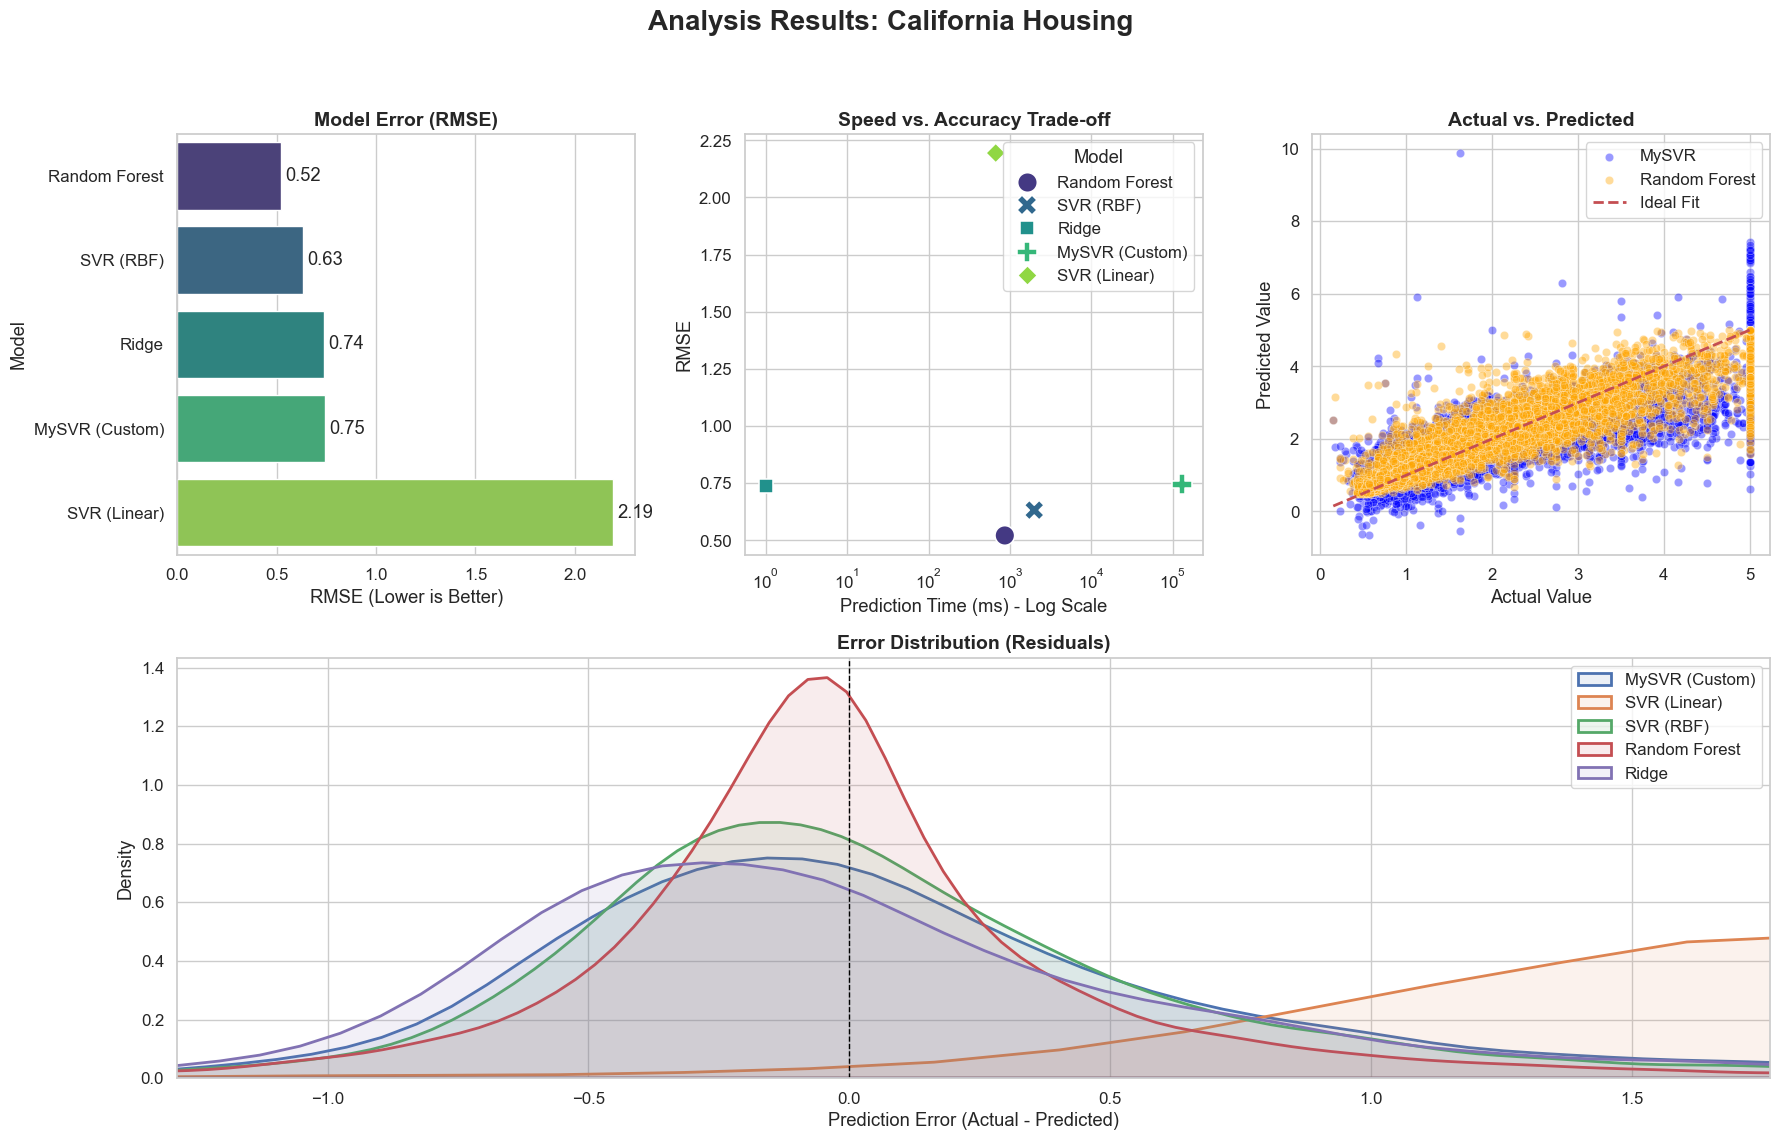


Final Results Table (California):


,Model,RMSE,MAE,R2,Time (ms)
3,Random Forest,0.521644,0.342817,0.796735,864.726067
2,SVR (RBF),0.632485,0.448383,0.701176,1986.046314
4,Ridge,0.737268,0.533679,0.593963,1.002073
0,MySVR (Custom),0.745660,0.521123,0.584667,129386.075258
1,SVR (Linear),2.194282,1.934572,-2.596664,668.842077


In [35]:
# California Housing 
# Task: Predict median house value based on features like income, location, etc.

print("Loading California Housing Dataset...")
data_cal = fetch_california_housing()
X_cal, y_cal = data_cal.data, data_cal.target

# Execute Unified Experiment
results_table_cal = run_experiment("California Housing", X_cal, y_cal)

print("\nFinal Results Table (California):")
display(results_table_cal)

Loading Diabetes Dataset...

STARTING EXPERIMENT: Diabetes
Dataset Shape: (442, 10) samples, 10 features
Running MySVR (Custom)... Done. RMSE: 53.7446
Running SVR (Linear)... Done. RMSE: 53.6305
Running SVR (RBF)... Done. RMSE: 52.6987
Running Random Forest... Done. RMSE: 54.7900
Running Ridge... Done. RMSE: 53.3114


c:\Users\Tzagkari\Desktop\Coding\Τεχνητή Νοημοσύνη ΑΠΘ\1ο Εξάμηνο\Υπολογιστική Νοημοσύνη - Στατιστική Μάθηση\NNclass\.venv\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


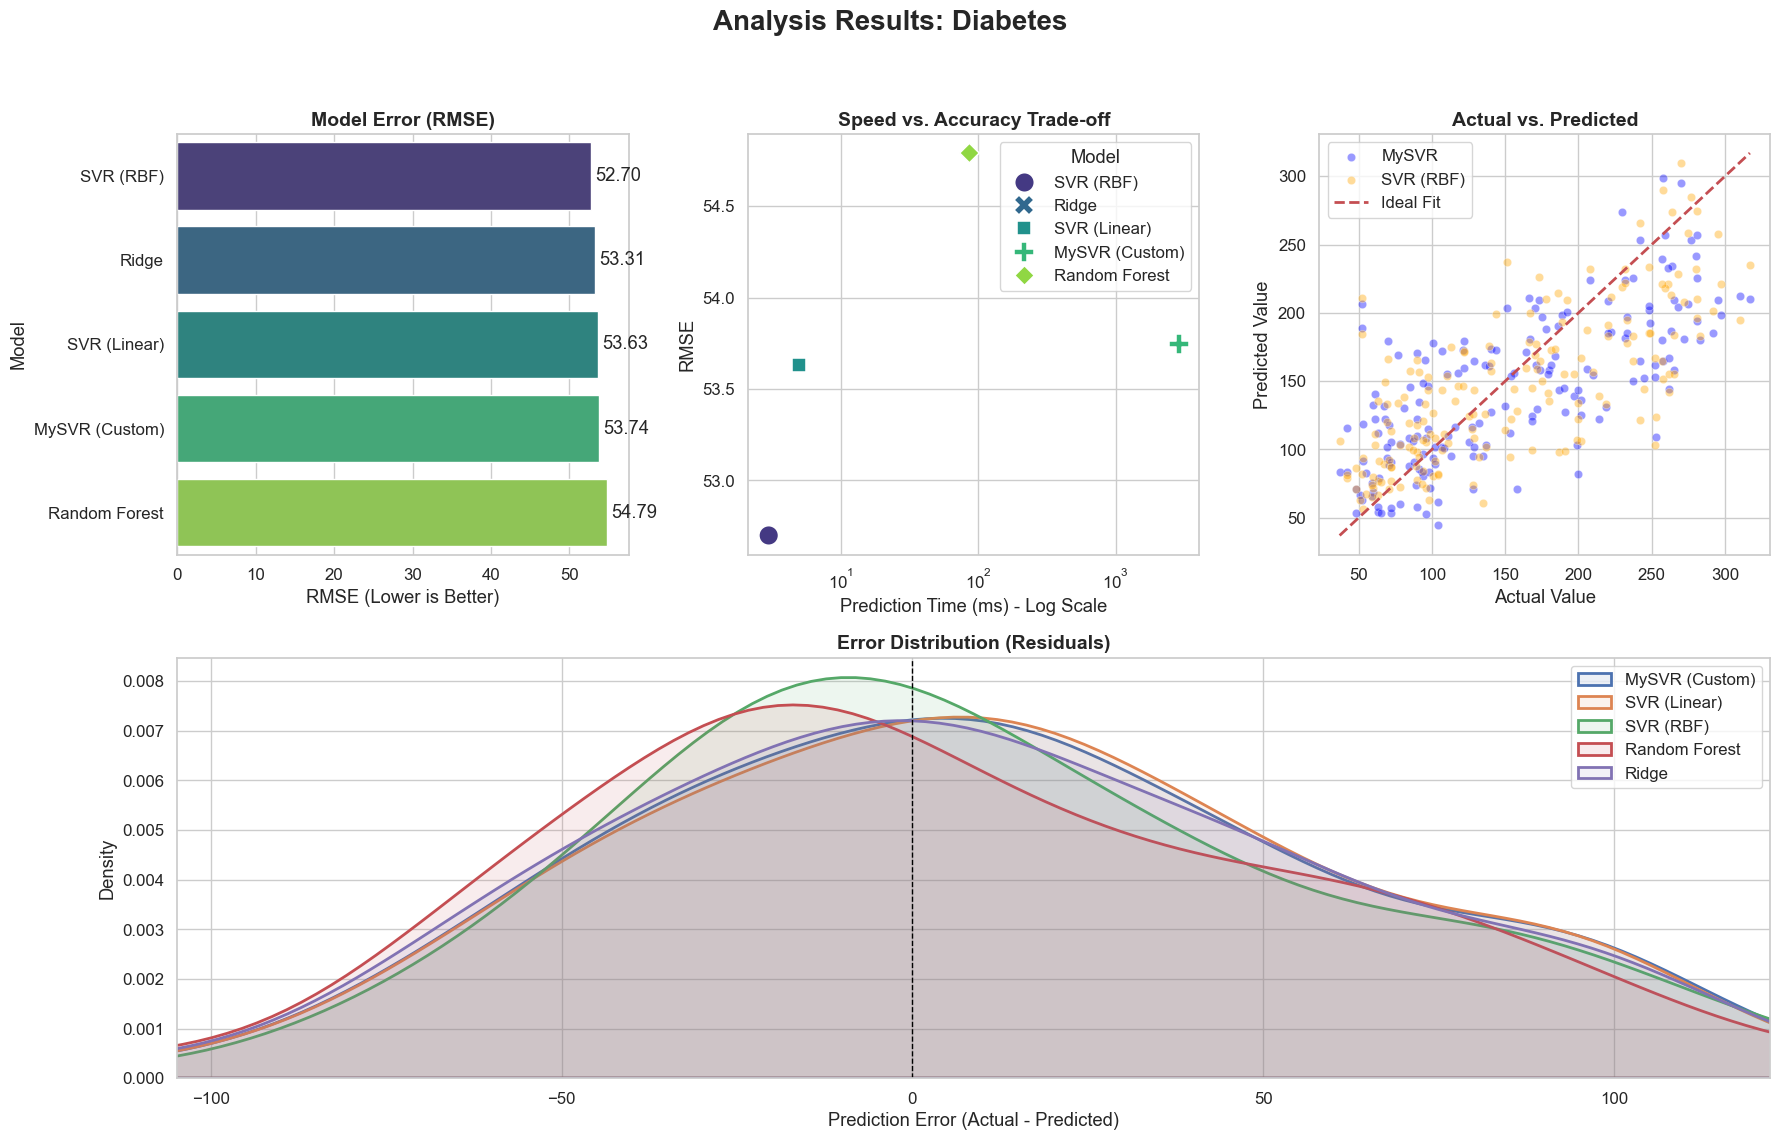


Final Results Table (Diabetes):


,Model,RMSE,MAE,R2,Time (ms)
2,SVR (RBF),52.698709,40.921117,0.525289,3.000736
4,Ridge,53.311406,42.568010,0.514186,0.000000
1,SVR (Linear),53.630538,42.649582,0.508353,5.001068
0,MySVR (Custom),53.744649,42.711451,0.506258,2871.380091
3,Random Forest,54.789952,43.645028,0.486866,86.276293


In [36]:
# Experiment 2: Diabetes Dataset 
# Task: Predict disease  (quantitative measure) one year after baseline.

print("Loading Diabetes Dataset...")
data_dia = load_diabetes()
X_dia, y_dia = data_dia.data, data_dia.target

# Execute Unified Experiment
results_table_dia = run_experiment("Diabetes", X_dia, y_dia)

print("\nFinal Results Table (Diabetes):")
display(results_table_dia)